# HASTS206 Assignment 2: Part 2: Population projections

**All data are hypothetical (synthetic).** Run from the repository root. The first code cell runs the previous part (`part3_life_table.ipynb`) so that all earlier variables exist.

In [ ]:
%run part3_life_table.ipynb

## 2. Population projections
### Choice of projection district
The brief asks for one of the two contrasting districts to be used for the age-sex projection. I use the **ageing district** (see the next cell for the evidence). Its 2020-2025 trend is *upward*, but the 2025 balance is already *negative* (deaths exceed births and net migration is negative). Simple trend extrapolation therefore points the wrong way, which makes it the most informative case for comparing extrapolation with a cohort-component model. The young district is projected as well (for the dashboard), but the report focuses on the ageing district.

In [14]:
# What this cell does: Chooses the projection district and shows its 2020, 2025 and 2026 populations
# and the growth in each period.
PROJ = SEL_O
pop20 = districts.set_index('district_id').population_2020
pop25 = rec.set_index('district_id').pop2025
pop26 = districts.set_index('district_id').population_2026
cmp = pd.DataFrame({'pop_2020': pop20, 'pop_2025': pop25, 'pop_2026_reported': pop26})
cmp['change_2020_25_pct'] = 100 * (cmp.pop_2025 / cmp.pop_2020 - 1)
cmp['change_2025_26_pct'] = 100 * (cmp.pop_2026_reported / cmp.pop_2025 - 1)
cmp.loc[[SEL_Y, SEL_O]]

,pop_2020,pop_2025,pop_2026_reported,change_2020_25_pct,change_2025_26_pct
district_id,,,,,
D01,156609,172445,173752,10.1118,0.7579
D24,157945,172718,171049,9.3533,-0.9663


**Notes: why we project the ageing district.** D24 grew 9.4% from 2020 to 2025 but then fell 0.97% during 2025. The past trend and what is happening now disagree. That makes it the best case for testing whether a simple trend line is good enough. D01 (10.1% and then 0.76%) is consistent with its own trend, so it would teach us less.

### 2(a) Arithmetic and geometric growth
With opening counts P(2020) and P(2025) (t = 5 years):
- **Arithmetic:** P(t) = P(2025) + g t, with g = (P2025 - P2020)/5 persons per year
- **Geometric:** P(t) = P(2025)(1 + r)^t, with r = (P2025/P2020)^(1/5) - 1

In [15]:
# What this cell does: Fits the arithmetic and geometric growth models to the 2020 and 2025 counts,
# projects them to 2030, and back-tests both against the reported 2026 population.
def trend_models(d):
    p0, p5, p6 = pop20[d], pop25[d], pop26[d]
    g = (p5 - p0) / 5; r = (p5 / p0) ** (1 / 5) - 1
    return dict(district_id=d, P2020=p0, P2025=p5, P2026_reported=p6, arith_annual_change=g, geom_rate=r,
                arith_2026=p5 + g, geom_2026=p5 * (1 + r), arith_2030=p5 + 5 * g, geom_2030=p5 * (1 + r) ** 5)
trend_all = pd.DataFrame([trend_models(d) for d in districts.district_id])
tr = trend_all.set_index('district_id').loc[[PROJ]].T
print(f'Projection district: {PROJ}'); print(tr.to_string())
t = trend_all.set_index('district_id').loc[PROJ]
print(f'\nBack-test against the reported 1 Jan 2026 stock ({t.P2026_reported:,.0f}):')
print(f'  arithmetic 2026 = {t.arith_2026:,.0f} (error {t.arith_2026 - t.P2026_reported:+,.0f});  geometric 2026 = {t.geom_2026:,.0f} (error {t.geom_2026 - t.P2026_reported:+,.0f})')
KEY['trend'] = {k: float(v) for k, v in t.items() if k != 'district_id'}

Projection district: D24
district_id                  D24
P2020                    157,945
P2025                    172,718
P2026_reported           171,049
arith_annual_change   2,954.6000
geom_rate                 0.0180
arith_2026          175,672.6000
geom_2026           175,834.4406
arith_2030               187,491
geom_2030           188,872.7565

Back-test against the reported 1 Jan 2026 stock (171,049):
  arithmetic 2026 = 175,673 (error +4,624);  geometric 2026 = 175,834 (error +4,785)


**Notes: arithmetic and geometric fits for D24.**
- The arithmetic model adds 2,955 people a year and reaches **187,491** by 2030. The geometric model grows 1.80% a year and reaches **188,873**. Geometric is a bit higher because the percentage is applied to a growing base.
- **Back-test:** we also ran both models forward one year and compared them with the real 2026 count (171,049). They give 175,673 and 175,834, which is about 4,624 too high after only one year. The trend models only see two totals. They cannot see that deaths now exceed births, so they keep going up.

In [16]:
# What this cell does: Checks the exponential (continuous growth) model from Unit 6 and shows it gives
# the same 2030 number as the geometric model.
# Extra check from Unit 6: the continuous (exponential) rate g = ln(P2025/P2020)/5 reproduces the geometric result
g_cont = np.log(t.P2025 / t.P2020) / 5
exp_2030 = t.P2025 * np.exp(5 * g_cont)
print(f'Continuous rate g = {g_cont:.5f} per year; effective annual rate e^g - 1 = {np.exp(g_cont)-1:.5f} (geometric r = {t.geom_rate:.5f})')
print(f'Exponential P(2030) = {exp_2030:,.1f}   Geometric P(2030) = {t.geom_2030:,.1f}   difference = {exp_2030 - t.geom_2030:.2e}')

Continuous rate g = 0.01788 per year; effective annual rate e^g - 1 = 0.01804 (geometric r = 0.01804)
Exponential P(2030) = 188,872.8   Geometric P(2030) = 188,872.8   difference = 1.16e-10


**Notes: exponential check.** The continuous rate is 0.0179 a year, and e^g - 1 equals the geometric rate. The exponential and geometric answers for 2030 are the same to many decimal places. This is a good check because the lecture notes say the two are the same model written two ways.

In [17]:
# What this cell does: Builds a small table that labels each input as an estimate or an assumption and
# each 2030 result as a conditional projection.
inputs = pd.DataFrame([
    ['population_2020, population_2026', 'Opening stocks on 1 January (counts from the data file)', 'Estimate / observed input'],
    ['population_2025 (sum of age_sex)', 'Opening stock on 1 Jan 2025 derived by summing 36 age-sex cells', 'Estimate (derived)'],
    ['births, deaths, arrivals, departures 2025', 'Calendar-2025 event counts; close the balance exactly', 'Estimate / observed input'],
    ['survival_5yr, newborn_survival_f/m', 'Supplied scenario inputs (not derived from the data)', 'Assumption (input)'],
    ['fertility, arrivals, departures multipliers', 'Scenario scalars applied to 2025 flows', 'Assumption (input)'],
    ['Arithmetic and geometric P(2030)', 'Extrapolate the 2020-25 trend', 'Conditional projection'],
    ['Cohort-component P(2030) by scenario', 'Conditional on survival, fertility, migration and timing assumptions', 'Conditional projection'],
], columns=['Item', 'What it is', 'Classification'])
inputs

,Item,What it is,Classification
0,"population_2020, population_2026",Opening stocks on 1 January (counts from the d...,Estimate / observed input
1,population_2025 (sum of age_sex),Opening stock on 1 Jan 2025 derived by summing...,Estimate (derived)
2,"births, deaths, arrivals, departures 2025",Calendar-2025 event counts; close the balance ...,Estimate / observed input
3,"survival_5yr, newborn_survival_f/m",Supplied scenario inputs (not derived from the...,Assumption (input)
4,"fertility, arrivals, departures multipliers",Scenario scalars applied to 2025 flows,Assumption (input)
5,Arithmetic and geometric P(2030),Extrapolate the 2020-25 trend,Conditional projection
6,Cohort-component P(2030) by scenario,"Conditional on survival, fertility, migration ...",Conditional projection


**Notes: estimates versus projections.** Counts such as the 2020, 2025 and 2026 populations and the 2025 events are estimates of things that already happened. Survival probabilities, newborn survival and the scenario multipliers are assumptions given to us. Every 2030 number depends on those assumptions, so it is a conditional projection (what would happen if they hold) and not a forecast.

### 2(b) Five-year cohort-component projection (1 Jan 2025 to 1 Jan 2030)
**Timing assumptions (documented):**
1. Each opening cohort is advanced by its supplied five-year survival probability; people aged 80-84 move to 85+, and 85+ retains survivors of the open group.
2. Births over the five years = 5 x (2025 births to women classified by baseline age) x fertility multiplier, split 49% female / 51% male, then multiplied by scenario newborn survival (survival from birth to the end of the interval, averaged over birth dates). Survivors enter ages 0-4.
3. Migration = 5 x each 2025 flow x scenario multiplier, applied as an **end-of-period adjustment** by destination age and sex. Migrants are therefore not exposed to mortality (or fertility) during the interval, and newborns are not exposed to migration.
4. Births are driven by 2025 baseline women. Female cohorts are not re-aged for fertility during the projection (no age-specific fertility feedback).

In [18]:
# What this cell does: Defines the cohort-component function and runs it for D24 under Low, Base and
# High: survival, newborns and migration are added in the order the brief describes, and the
# accounting is checked.
SCEN = scen.set_index('scenario')

def cohort_component(d, s_row, fert=None, arr=None, dep=None):
    """Return dict with projected age-sex table and accounting components for district d and scenario row s_row (a Series)."""
    fm = s_row.fertility_multiplier if fert is None else fert
    am = s_row.arrivals_multiplier if arr is None else arr
    dm = s_row.departures_multiplier if dep is None else dep
    g = age_sex[age_sex.district_id == d]
    piv = lambda col: g.pivot(index='age_start', columns='sex', values=col).loc[AGES, ['F', 'M']]
    P, S, A, D, B = piv('population_2025'), piv('survival_5yr'), piv('arrivals_2025'), piv('departures_2025'), piv('births_to_women_2025')
    surv = P * S
    adv = pd.DataFrame(0.0, index=AGES, columns=['F', 'M'])
    last = len(AGES) - 1
    for i in range(len(AGES)):
        adv.iloc[min(i + 1, last)] += surv.iloc[i]        # 80-84 -> 85+ ; 85+ -> 85+ (retention)
    births_all = 5 * B['F'].sum() * fm
    births = {'F': 0.49 * births_all, 'M': 0.51 * births_all}
    nb_surv = {'F': births['F'] * s_row.newborn_survival_f, 'M': births['M'] * s_row.newborn_survival_m}
    adv.iloc[0] += pd.Series(nb_surv)
    net_in = 5 * A * am
    net_out = 5 * D * dm
    proj = adv + net_in - net_out
    comp = dict(start=P.values.sum(), cohort_deaths=(P - surv).values.sum(), births=births_all, newborn_deaths=births_all - sum(nb_surv.values()),
                surviving_births=sum(nb_surv.values()), arrivals=net_in.values.sum(), departures=net_out.values.sum(), end=proj.values.sum())
    comp['net_migration'] = comp['arrivals'] - comp['departures']
    comp['end_by_identity'] = comp['start'] - comp['cohort_deaths'] - comp['newborn_deaths'] + comp['births'] + comp['net_migration']
    comp['accounting_gap'] = comp['end'] - comp['end_by_identity']
    comp['min_cell'] = proj.values.min()
    return proj, comp, P

def shares(proj):
    t = proj.values.sum(); u = proj.loc[[0, 5, 10]].values.sum(); o = proj.loc[[a for a in AGES if a >= 65]].values.sum()
    return u / t, o / t

rows = []; proj_store = {}
for s in ['Low', 'Base', 'High']:
    proj, comp, P = cohort_component(PROJ, SCEN.loc[s])
    proj_store[s] = proj
    u, o = shares(proj)
    rows.append(dict(scenario=s, **comp, share_u15=u, share_65p=o, age0_4=proj.loc[0].sum()))
cc = pd.DataFrame(rows).set_index('scenario')
print(f'Cohort-component accounting for {PROJ} (persons, 1 Jan 2025 -> 1 Jan 2030)')
cc[['start', 'cohort_deaths', 'births', 'newborn_deaths', 'surviving_births', 'arrivals', 'departures', 'net_migration', 'end', 'end_by_identity', 'accounting_gap', 'min_cell']].T

Cohort-component accounting for D24 (persons, 1 Jan 2025 -> 1 Jan 2030)


scenario,Low,Base,High
start,"172,718","172,718","172,718"
cohort_deaths,"15,269.2679","15,269.2679","15,269.2679"
births,"9,666.8000","10,985","12,303.2000"
newborn_deaths,324.5145,286.4888,209.8926
surviving_births,"9,342.2855","10,698.5112","12,093.3074"
arrivals,"11,648.1000","14,205","16,761.9000"
departures,"17,298.4000","15,445","13,591.6000"
net_migration,"-5,650.3000","-1,240","3,170.3000"
end,"161,140.7176","166,907.2433","172,712.3395"
end_by_identity,"161,140.7176","166,907.2433","172,712.3395"


**Notes: cohort-component accounting for D24.** In the Base scenario we start with 172,718 people. We remove 15,556 deaths (15,269 among the people already there and 286 among new babies), add 10,985 births, and add -1,240 net migrants. That gives **166,907**. The fall is mostly natural decrease (-4,571), not migration. Across scenarios only fertility, migration and newborn survival change, so the total ranges from 161,141 (Low) to 172,712 (High). The timing assumption is that migrants arrive at the end of the five years, so they are not exposed to death during the period.

In [19]:
# What this cell does: Checks that start - deaths + births + net migration equals the sum of all
# projected cells, for each scenario, and that no cell is negative.
print('Verification of accounting totals:')
for s in cc.index:
    r = cc.loc[s]
    print(f'  {s:4s}: start {r.start:,.0f} - deaths {r.cohort_deaths + r.newborn_deaths:,.0f} + births {r.births:,.0f} + net migration {r.net_migration:+,.0f} = {r.end_by_identity:,.1f};  '
          f'sum of projected cells = {r.end:,.1f};  gap = {r.accounting_gap:.2e};  smallest cell = {r.min_cell:,.0f}')
    assert abs(r.accounting_gap) < 1e-6 and r.min_cell >= 0
print('\nBase scenario projected population by age band and sex, 1 Jan 2030:')
b = proj_store['Base'].copy(); b.index = [AGE_LAB[a] for a in b.index]; b['Total'] = b.sum(axis=1)
b.round(0)

Verification of accounting totals:
  Low : start 172,718 - deaths 15,594 + births 9,667 + net migration -5,650 = 161,140.7;  sum of projected cells = 161,140.7;  gap = 0.00e+00;  smallest cell = 2,046
  Base: start 172,718 - deaths 15,556 + births 10,985 + net migration -1,240 = 166,907.2;  sum of projected cells = 166,907.2;  gap = -2.91e-11;  smallest cell = 2,121
  High: start 172,718 - deaths 15,479 + births 12,303 + net migration +3,170 = 172,712.3;  sum of projected cells = 172,712.3;  gap = 0.00e+00;  smallest cell = 2,195

Base scenario projected population by age band and sex, 1 Jan 2030:


,F,M,Total
0-4,"5,244","5,429","10,674"
5-9,"2,121","2,155","4,276"
10-14,"2,672","2,231","4,903"
15-19,"3,885","3,256","7,142"
20-24,"3,400","3,974","7,374"
25-29,"4,579","3,944","8,523"
30-34,"5,889","4,709","10,598"
35-39,"5,521","5,521","11,043"
40-44,"5,899","5,582","11,481"
45-49,"4,883","4,826","9,709"


**Notes: checking the accounting.** For every scenario, the balancing equation and the sum of the 36 projected age-sex cells agree to within about 1e-11, which is rounding error, and no cell is negative (the smallest has 2,046 people). The 85+ cell gets survivors from 80-84 and the people already in 85+, as the brief says.

In [20]:
# What this cell does: Writes an assumptions register: base date, projection date, geography, age
# groups, sources and every assumption used.
# Assumptions register (Unit 6: record base date, boundary, age groups, horizon, sources and assumptions)
assump = pd.DataFrame([
    ['Base date', '1 January 2025 (age-sex file); trend fit also uses 1 January 2020'],
    ['Projection date and horizon', '1 January 2030, one five-year step'],
    ['Geography', f'{PROJ}, fixed boundary (district-level flows cross the boundary, so migration matters)'],
    ['Age groups', '18 five-year bands, 0-4 to 85+ (open), by sex'],
    ['Data sources', 'Synthetic CSVs supplied with the assignment (hypothetical)'],
    ['Survival', 'Supplied five-year survival probabilities, by age and sex, used unchanged'],
    ['Fertility', '5 x 2025 births to women x scenario factor; 49% female / 51% male'],
    ['Newborn survival', 'Scenario rates, average from birth to end of the interval'],
    ['Migration', '5 x 2025 flows x scenario multipliers, added at the END of the period by destination age and sex'],
    ['Not modelled', 'Changes in age pattern of fertility, mortality trends, migration changes within the period, random variation'],
], columns=['Item', 'Assumption used'])
assump

,Item,Assumption used
0,Base date,1 January 2025 (age-sex file); trend fit also ...
1,Projection date and horizon,"1 January 2030, one five-year step"
2,Geography,"D24, fixed boundary (district-level flows cros..."
3,Age groups,"18 five-year bands, 0-4 to 85+ (open), by sex"
4,Data sources,Synthetic CSVs supplied with the assignment (h...
5,Survival,"Supplied five-year survival probabilities, by ..."
6,Fertility,5 x 2025 births to women x scenario factor; 49...
7,Newborn survival,"Scenario rates, average from birth to end of t..."
8,Migration,"5 x 2025 flows x scenario multipliers, added a..."
9,Not modelled,"Changes in age pattern of fertility, mortality..."


**Notes: assumptions register.** This follows the Unit 6 checklist for reporting a projection. The most important line to remember is the last one: we do not model changes in the age pattern of fertility, mortality trends or random variation. So the results are conditional on a stable pattern for five years.

### 2(c) Comparison with trend models, shares, and a one-factor sensitivity

In [21]:
# What this cell does: Puts the arithmetic, geometric and three cohort-component totals in one table
# and adds the projected shares under 15 and aged 65+.
t = trend_all.set_index('district_id').loc[PROJ]
comp_tbl = pd.DataFrame({
    'Projected total 1 Jan 2030': [t.arith_2030, t.geom_2030] + cc.end.tolist(),
    'Share under 15': [np.nan, np.nan] + cc.share_u15.tolist(),
    'Share 65+': [np.nan, np.nan] + cc.share_65p.tolist()},
    index=['Arithmetic', 'Geometric', 'Cohort-component Low', 'Cohort-component Base', 'Cohort-component High'])
comp_tbl['Change vs 2025'] = comp_tbl.iloc[:, 0] - pop25[PROJ]
comp_tbl['Change vs 2025 (%)'] = 100 * comp_tbl['Change vs 2025'] / pop25[PROJ]
comp_tbl['Gap to CC Base'] = comp_tbl.iloc[:, 0] - cc.loc['Base', 'end']
comp_tbl.index.name = f'{PROJ} (opening 2025 = {pop25[PROJ]:,})'
KEY['cc'] = cc.round(4).to_dict('index'); KEY['comp'] = comp_tbl.round(4).to_dict('index')
comp_tbl

,Projected total 1 Jan 2030,Share under 15,Share 65+,Change vs 2025,Change vs 2025 (%),Gap to CC Base
"D24 (opening 2025 = 172,718)",,,,,,
Arithmetic,"187,491",NaN,NaN,"14,773",8.5532,"20,583.7567"
Geometric,"188,872.7565",NaN,NaN,"16,154.7565",9.3533,"21,965.5132"
Cohort-component Low,"161,140.7176",0.1122,0.2772,"-11,577.2824",-6.7030,"-5,766.5257"
Cohort-component Base,"166,907.2433",0.1189,0.2751,"-5,810.7567",-3.3643,0
Cohort-component High,"172,712.3395",0.1255,0.2731,-5.6605,-0.0033,"5,805.0962"


**Notes: comparing the methods.**
- The arithmetic (187,491) and geometric (188,873) results are 20,584 to 21,966 people higher than the Base cohort-component result (166,907). The trend models say +8.6% to +9.4%. The cohort-component scenarios say -6.7% (Low), -3.4% (Base) and -0.00% (High). Even the optimistic High scenario shows no growth.
- **Shares in 2030:** under 15 goes from 9.7% now to 11.2% / 11.9% / 12.5% (Low / Base / High). The 65+ share is 27.7% / 27.5% / 27.3%, compared with 27.7% now, so the district stays very old.
- Part of the rise in the under-15 share is mechanical. See the data check after the sensitivity section.

In [22]:
# What this cell does: Takes the Base scenario and changes only the fertility multiplier (1.00 to
# 1.12), then measures the effect on ages 0-4.
# One-factor sensitivity: Base scenario, change ONLY the fertility multiplier from 1.00 to the High value (1.12)
hi_f = SCEN.loc['High', 'fertility_multiplier']
p_base, c_base, _ = cohort_component(PROJ, SCEN.loc['Base'])
p_sens, c_sens, _ = cohort_component(PROJ, SCEN.loc['Base'], fert=hi_f)
p_high, c_high, _ = cohort_component(PROJ, SCEN.loc['High'])
a_b, a_s, a_h = p_base.loc[0].sum(), p_sens.loc[0].sum(), p_high.loc[0].sum()
sens = pd.DataFrame({'Base': [a_b, c_base['end'], *shares(p_base)], 'Base + High fertility only': [a_s, c_sens['end'], *shares(p_sens)], 'Full High scenario': [a_h, c_high['end'], *shares(p_high)]},
                    index=['Ages 0-4 (persons)', 'Total population', 'Share under 15', 'Share 65+'])
print(sens.to_string())
print(f'\nFertility multiplier 1.00 -> {hi_f:.2f} (+{100*(hi_f-1):.0f}%):')
print(f'  Ages 0-4: {a_b:,.0f} -> {a_s:,.0f}  (change {a_s - a_b:+,.0f} persons, {100*(a_s/a_b-1):+.2f}% )')
print(f'  Surviving births rise by {c_sens["surviving_births"] - c_base["surviving_births"]:,.0f} = 0.12 x Base surviving births {c_base["surviving_births"]:,.0f} = {0.12*c_base["surviving_births"]:,.0f}  (linear, migration unchanged)')
print(f'  Share of the full High-vs-Base gap in ages 0-4 explained by fertility alone: {100*(a_s-a_b)/(a_h-a_b):.1f}%')
KEY['sens'] = dict(a_b=a_b, a_s=a_s, a_h=a_h, delta=a_s - a_b, pct=100 * (a_s / a_b - 1), tot_b=c_base['end'], tot_s=c_sens['end'])

                           Base  Base + High fertility only  Full High scenario
Ages 0-4 (persons)  10,673.5112                 11,957.3325         12,192.8074
Total population   166,907.2433                168,191.0646        172,712.3395
Share under 15           0.1189                      0.1257              0.1255
Share 65+                0.2751                      0.2730              0.2731

Fertility multiplier 1.00 -> 1.12 (+12%):
  Ages 0-4: 10,674 -> 11,957  (change +1,284 persons, +12.03% )
  Surviving births rise by 1,284 = 0.12 x Base surviving births 10,699 = 1,284  (linear, migration unchanged)
  Share of the full High-vs-Base gap in ages 0-4 explained by fertility alone: 84.5%


**Notes: fertility sensitivity.**
- **Effect:** ages 0-4 go up by **1,284 children (+12.03%)**, to 11,957. That is exactly 12% of the Base surviving births. The total rises by the same amount because only the 0-4 group changes, and it is still below the 2025 population.
- Fertility alone explains 84.5% of the gap between High and Base in ages 0-4. The rest comes from better newborn survival and migration.
- **One planning implication:** early-childhood, maternity and primary-school capacity should be planned for a range and not one number. For example, at an illustrative 40 pupils per class, the extra 1,284 children would need about 32 more classrooms. Because the total population still falls, child services have to be planned separately from the overall trend.
- **One limitation:** the multiplier is one number applied to 2025 births. It ignores any change in the age pattern of fertility and the fact that the mothers get older during five years.

In [23]:
# What this cell does: Changes one Base input at a time to its High value (fertility, arrivals,
# departures, newborn survival) and records the effect on the 2030 total and on ages 0-4.
# Which assumption matters most? Change ONE Base input at a time to its High-scenario value (Unit 6: show which assumptions drive the result)
base_row, high_row = SCEN.loc['Base'], SCEN.loc['High']
one_at_a_time = []
def run_variant(label, row_changes=None, **kw):
    row = base_row.copy()
    for k_, v_ in (row_changes or {}).items(): row[k_] = v_
    pr, cm, _ = cohort_component(PROJ, row, **kw)
    one_at_a_time.append(dict(change=label, total_2030=cm['end'], change_in_total=cm['end'] - c_base['end'], ages_0_4=pr.loc[0].sum(), change_in_0_4=pr.loc[0].sum() - a_b))
run_variant('Fertility 1.00 to 1.12', fert=high_row.fertility_multiplier)
run_variant('Arrivals multiplier 1.00 to 1.18', arr=high_row.arrivals_multiplier)
run_variant('Departures multiplier 1.00 to 0.88', dep=high_row.departures_multiplier)
run_variant('Newborn survival to High values', row_changes=dict(newborn_survival_f=high_row.newborn_survival_f, newborn_survival_m=high_row.newborn_survival_m))
one_at_a_time = pd.DataFrame(one_at_a_time)
KEY['oat'] = one_at_a_time.round(2).to_dict('records')
one_at_a_time

,change,total_2030,change_in_total,ages_0_4,change_in_0_4
0,Fertility 1.00 to 1.12,"168,191.0646","1,283.8213","11,957.3325","1,283.8213"
1,Arrivals multiplier 1.00 to 1.18,"169,464.1433","2,556.9000","10,746.4112",72.9000
2,Departures multiplier 1.00 to 0.88,"168,760.6433","1,853.4000","10,725.1112",51.6000
3,Newborn survival to High values,"167,006.3280",99.0847,"10,772.5959",99.0847


**Notes: which assumption matters most?** For the 2030 **total**, the biggest single effect is the arrivals multiplier (2,557 people), then departures (1,853), then fertility (1,284), and newborn survival has very little effect (99). For **ages 0-4**, fertility dominates (1,284 children), while migration adds only about 73 and 52. So the answer depends on the question: migration matters most for the total, fertility matters most for the number of young children.

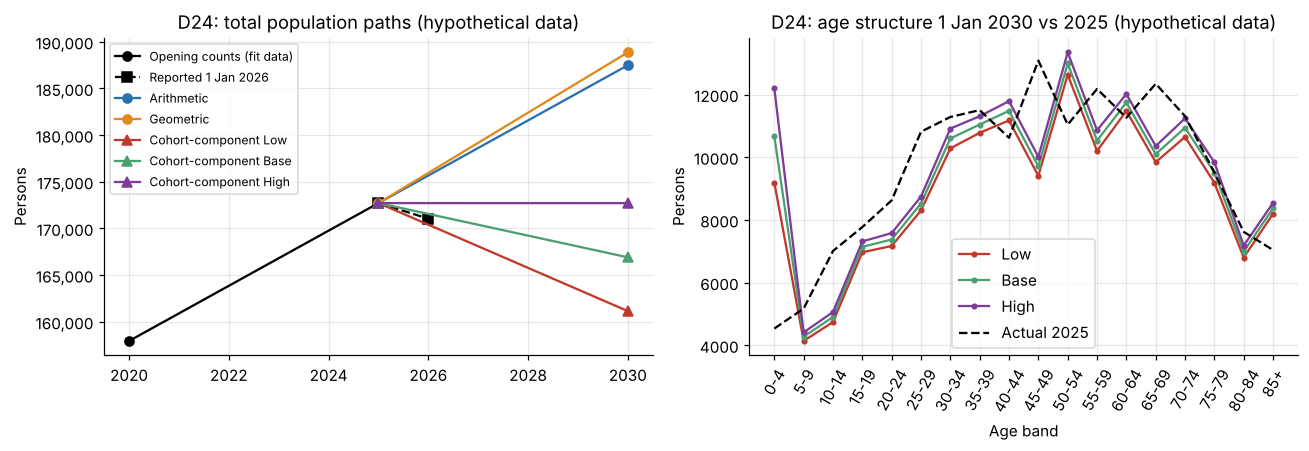

In [24]:
# What this cell does: Draws two charts: the paths of all projections from 2020 to 2030, and the age
# structure in 2030 compared with 2025.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot([2020, 2025], [pop20[PROJ], pop25[PROJ]], 'ko-', label='Opening counts (fit data)')
ax[0].plot([2025, 2026], [pop25[PROJ], pop26[PROJ]], 'k--', marker='s', label='Reported 1 Jan 2026')
ax[0].plot([2025, 2030], [pop25[PROJ], t.arith_2030], color='#2a6fb0', marker='o', label='Arithmetic')
ax[0].plot([2025, 2030], [pop25[PROJ], t.geom_2030], color='#e08a1e', marker='o', label='Geometric')
for s, c in zip(['Low', 'Base', 'High'], ['#c0392b', '#4c9f70', '#7d3c98']):
    ax[0].plot([2025, 2030], [pop25[PROJ], cc.loc[s, 'end']], color=c, marker='^', label=f'Cohort-component {s}')
ax[0].set_title(f'{PROJ}: total population paths {HYP}'); ax[0].set_ylabel('Persons'); ax[0].legend(fontsize=8)
ax[0].yaxis.set_major_formatter(lambda v, p: f'{v:,.0f}')
for s, c in zip(['Low', 'Base', 'High'], ['#c0392b', '#4c9f70', '#7d3c98']):
    v = proj_store[s].sum(axis=1)
    ax[1].plot([AGE_LAB[a] for a in AGES], v.values, color=c, marker='o', ms=3, label=s)
ax[1].plot([AGE_LAB[a] for a in AGES], age_sex[age_sex.district_id == PROJ].groupby('age_start').population_2025.sum().values, 'k--', label='Actual 2025')
ax[1].set_title(f'{PROJ}: age structure 1 Jan 2030 vs 2025 {HYP}'); ax[1].set_xlabel('Age band'); ax[1].set_ylabel('Persons'); ax[1].tick_params(axis='x', rotation=60); ax[1].legend()
fig.tight_layout(); fig.savefig(FIG / 'projections.png', dpi=150)

**Notes: the charts.** The left chart shows the trend models going up and the cohort-component scenarios going flat or down. The reported 2026 point is already below the 2025 population. The right chart shows the age structure for 2030. The 0-4 group jumps up, and the older groups carry on much as before, which leads into the next check.

In [25]:
# What this cell does: Runs the same projection for all 24 districts and the three scenarios (72 runs)
# and saves the results for the Power BI filters.
# Run the same engine for ALL 24 districts and 3 scenarios (feeds the Power BI district / scenario filter)
tot_rows, ag_rows = [], []
for d in districts.district_id:
    for s in ['Low', 'Base', 'High']:
        pr, cm, _ = cohort_component(d, SCEN.loc[s])
        u, o = shares(pr)
        tot_rows.append(dict(district_id=d, scenario=s, **{k: cm[k] for k in ['start', 'cohort_deaths', 'births', 'newborn_deaths', 'surviving_births', 'arrivals', 'departures', 'net_migration', 'end', 'accounting_gap']},
                             age0_4=pr.loc[0].sum(), share_u15=u, share_65p=o, pct_change=100 * (cm['end'] / cm['start'] - 1)))
        for a in AGES:
            for sx in ['F', 'M']:
                ag_rows.append(dict(district_id=d, scenario=s, age_start=a, age_band=AGE_LAB[a], sex=sx, projected_2030=pr.loc[a, sx]))
proj_tot = pd.DataFrame(tot_rows); proj_age = pd.DataFrame(ag_rows)
print('max |accounting gap| over 72 district-scenario runs:', proj_tot.accounting_gap.abs().max())
proj_tot.to_csv(OUT / 'projection_totals.csv', index=False); proj_age.to_csv(OUT / 'projection_age_sex.csv', index=False); trend_all.to_csv(OUT / 'projection_trend_models.csv', index=False)
proj_tot[proj_tot.district_id.isin([SEL_Y, SEL_O])].round(1)

max |accounting gap| over 72 district-scenario runs: 5.820766091346741e-11


,district_id,scenario,start,cohort_deaths,births,newborn_deaths,surviving_births,arrivals,departures,net_migration,end,accounting_gap,age0_4,share_u15,share_65p,pct_change
0,D01,Low,172445,"9,123","17,331.6000",581.8000,"16,749.8000","10,086","16,385.6000","-6,299.6000","173,772.2000",0,"16,005.3000",0.3000,0.1000,0.8000
1,D01,Base,172445,"9,123","19,695",513.6000,"19,181.4000","12,300","14,630","-2,330","180,173.3000",0,"18,831.4000",0.3000,0.1000,4.5000
2,D01,High,172445,"9,123","22,058.4000",376.3000,"21,682.1000","14,514","12,874.4000","1,639.6000","186,643.7000",0,"21,726.6000",0.3000,0.1000,8.2000
69,D24,Low,172718,"15,269.3000","9,666.8000",324.5000,"9,342.3000","11,648.1000","17,298.4000","-5,650.3000","161,140.7000",0,"9,192.8000",0.1000,0.3000,-6.7000
70,D24,Base,172718,"15,269.3000","10,985",286.5000,"10,698.5000","14,205","15,445","-1,240","166,907.2000",-0,"10,673.5000",0.1000,0.3000,-3.4000
71,D24,High,172718,"15,269.3000","12,303.2000",209.9000,"12,093.3000","16,761.9000","13,591.6000","3,170.3000","172,712.3000",0,"12,192.8000",0.1000,0.3000,-0


**Notes: all districts.** We run the same projection function for all 24 districts and all three scenarios, which is 72 runs, and the biggest accounting gap is about 1e-11, effectively zero. The results are saved as CSV files for the Power BI district and scenario filters.

In [26]:
# What this cell does: Checks whether 5 x 2025 births is consistent with the size of the 0-4
# population we can see, and shows what the projection would look like if it were.
# Data-consistency diagnostic: is "5 x 2025 births" consistent with the observed size of the 0-4 cohort?
c04 = age_sex[(age_sex.district_id == PROJ) & (age_sex.age_start == 0)].population_2025.sum()
b25 = districts.set_index('district_id').births_2025[PROJ]
ratio_all = (5 * districts.set_index('district_id').births_2025 / age_sex[age_sex.age_start == 0].groupby('district_id').population_2025.sum())
implied_mult = (c04 / 5) / b25
p_cons, c_cons, _ = cohort_component(PROJ, SCEN.loc['Base'], fert=implied_mult)
print(f'{PROJ}: observed 0-4 cohort on 1 Jan 2025 = {c04:,}; 5 x 2025 births = {5*b25:,} (ratio {5*b25/c04:.2f})')
print(f'Number of districts where 5 x births exceeds the 0-4 cohort by more than 50%: {(ratio_all > 1.5).sum()} of 24')
print(f'Fertility multiplier that would make 5 x births equal the observed cohort: {implied_mult:.2f}')
print(f'Base projection of ages 0-4 in 2030: {a_b:,.0f} (as specified) vs {p_cons.loc[0].sum():,.0f} (consistency-adjusted); total {c_base["end"]:,.0f} vs {c_cons["end"]:,.0f}')
KEY['cons'] = dict(c04=c04, b5=5 * b25, ratio=5 * b25 / c04, n_dist=int((ratio_all > 1.5).sum()), mult=implied_mult, a04_adj=p_cons.loc[0].sum(), tot_adj=c_cons['end'])

D24: observed 0-4 cohort on 1 Jan 2025 = 4,535; 5 x 2025 births = 10,985 (ratio 2.42)
Number of districts where 5 x births exceeds the 0-4 cohort by more than 50%: 16 of 24
Fertility multiplier that would make 5 x births equal the observed cohort: 0.41
Base projection of ages 0-4 in 2030: 10,674 (as specified) vs 4,392 (consistency-adjusted); total 166,907 vs 160,625


**Notes: a data check we want to be open about.** In D24, five years of births at the 2025 level (10,985) is 2.42 times the number of children actually aged 0-4 (4,535). This happens in 16 of the 24 districts. For the young group the two agree. So the jump in ages 0-4 in the Base projection (from 4,535 to 10,674) is partly just a result of the rule "5 x 2025 births". It could mean fertility recently went up, or that births are over-recorded in this made-up data. If births were scaled to match the observed cohort (multiplier 0.41), the 0-4 group in 2030 would be about 4,392 and the total 160,625. We follow the brief in the main results and report this as a limitation.